# Finding topics: TF-IDF + embeddings + clustering

In this notebook I try to find groups of similar complaints.
The idea is to describe each complaint in two ways (word-based TF-IDF and meaning-based sentence embeddings), combine them, and then try a few clustering methods to see which one gives the most sensible groups.

The input is `complaints_clean.csv` from the data analysis notebook.
At the end I name the clusters, merge them into a final taxonomy of 12 topics, and save both for the labelling notebook.

## 1. Setup

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score, silhouette_score

In [4]:
import warnings
warnings.filterwarnings('ignore')

SEED = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 100)

In [5]:
df = pd.read_csv('../data/clean/complaints_clean.csv')
df.shape

(20551, 14)

In [6]:
df[['complaint_id', 'issue', 'product_group', 'n_words']].head()

,complaint_id,issue,product_group,n_words
0,1290253,"Loan servicing, payments, escrow account",Mortgage,67
1,1291150,"Loan servicing, payments, escrow account",Mortgage,182
2,1292174,Identity theft / Fraud / Embezzlement,Credit/prepaid card,193
3,1291516,Billing statement,Credit/prepaid card,15
4,1291026,Advertising and marketing,Credit/prepaid card,382


I only need a few columns here: `text` (original wording), `clean_text` (lowercase, no placeholders) and `issue` / `product_group`.
The last two are **not** used to build the clusters. I only use them later to check if the clusters make sense.

## 2. Word-based representation (TF-IDF)

TF-IDF gives a high score to words that are frequent in one complaint but rare in the others.

In [7]:
extra_stop = {'chase', 'bank', 'jpmorgan', 'would', 'could', 'also', 'get', 'got', 'one', 'told', 'said',
              'called', 'call', 'back', 'even', 'still', 'time', 'never', 'please', 'without', 'like',
              'know', 'want', 'asked', 'going', 'went', 'took', 'take', 'made', 'make', 'will'}
stop_words = list(ENGLISH_STOP_WORDS | extra_stop)
len(stop_words)

334

In [8]:
tfidf = TfidfVectorizer(stop_words=stop_words, ngram_range=(1, 2), min_df=10,
                        max_df=0.4, sublinear_tf=True, max_features=6000)
X = tfidf.fit_transform(df['clean_text'])
terms = np.array(tfidf.get_feature_names_out())
X.shape

(20551, 6000)

The matrix is very wide (one column per word or word pair), so I shrink it to 100 dense dimensions with SVD.
This keeps the main patterns and makes it possible to join it with the embeddings later.

In [9]:
svd = TruncatedSVD(n_components=200, random_state=SEED)
Z_tfidf = normalize(svd.fit_transform(X))
Z_tfidf.shape

(20551, 200)

In [10]:
round(svd.explained_variance_ratio_.sum(), 3)

np.float64(0.258)

## 3. Meaning-based representation (sentence embeddings)

An embedding model turns each complaint into a vector so that complaints with a similar meaning are close, even if they use different words.
I use `minishlab/potion-base-2M`, a static embedding model (Model2Vec): it is tiny (2M parameters, 64 dimensions) and very fast on a CPU.
I give it the original `text` and only remove the `XXXX` placeholders and the curly brackets around amounts.

In [11]:
df['embed_text'] = (df['text']
                    .str.replace(r'X{2,}(/X{2,})*(/\d{2,4})?', '', regex=True)
                    .str.replace(r'[{}]', '', regex=True)
                    .str.replace(r'\s+', ' ', regex=True)
                    .str.strip())
df['embed_text'].iloc[0][:200]

'I have an open and current mortgage with Chase Bank # . Chase is reporting the loan payments to but is surpressing the information and reporting the loan as Discharged in BK. This mortgage was reaffir'

One thing to keep in mind: a static model looks up a vector for every word piece and averages them, instead of running a transformer.
It reads the whole complaint (no length cut-off) and is fast, but it does not understand word order, so "I did not authorize" and "I authorized" look alike.
The TF-IDF block above has the same weakness, so the two views agree more than they would with a transformer model.

In [ ]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL = 'minishlab/potion-base-2M'
emb_file = Path('../data/interim/embeddings_potion-base-2M.npy')    # named after the model, so vectors of another model are never reused
if emb_file.exists():
    Z_emb = np.load(emb_file)
else:
    model = SentenceTransformer(EMBED_MODEL)
    Z_emb = model.encode(df['embed_text'].tolist(), batch_size=256,
                         show_progress_bar=True, normalize_embeddings=True)
    emb_file.parent.mkdir(parents=True, exist_ok=True)
    np.save(emb_file, Z_emb)
Z_emb.shape

Encoding takes only seconds with a static model; I still save the vectors, so every run of this notebook clusters exactly the same numbers.

In [ ]:
assert len(Z_emb) == len(df)
np.linalg.norm(Z_emb[:3], axis=1)

array([1., 1., 1.], dtype=float32)

## 4. Combine both representations

Both blocks have length 1, so I can mix them with a weight `alpha`.
With `alpha = 1` it is TF-IDF only, with `alpha = 0` it is embeddings only.
I use the square root of the weights so that the cosine similarity of the joined vectors is `alpha * (tfidf similarity) + (1 - alpha) * (embedding similarity)`.

In [ ]:
def combine(alpha):
    return np.hstack([np.sqrt(alpha) * Z_tfidf, np.sqrt(1 - alpha) * Z_emb])

In [ ]:
Z_demo = combine(0.5)
Z_demo.shape, np.linalg.norm(Z_demo[:3], axis=1)

((20551, 584), array([1.00000003, 1.00000001, 1.        ]))

## 5. How I will judge the clusters

Cluster scores like silhouette are weak for text, so I use several checks together:

- **NMI with `issue`**: how much the clusters agree with the issue the customer picked. I expect some agreement, not perfect.
- **Coherence**: do the top words of a cluster appear together in the same complaints?
- **Cluster sizes**: one giant cluster, or many tiny ones, are bad signs.
- **Unassigned %**: complaints a method refuses to put in a cluster (only some methods do this).
- **Silhouette**: only as a rough extra signal.
- And of course **reading the clusters** (section 9).

In [ ]:
Xbin = (X > 0).astype(np.float32).tocsc()
global_mean = np.asarray(X.mean(axis=0)).ravel()

In [ ]:
def cluster_top_terms(labels, topn=10):
    top = {}
    for c in sorted(set(labels[labels >= 0])):
        ids = np.where(labels == c)[0]
        mean_c = np.asarray(X[ids].mean(axis=0)).ravel()
        top[c] = (mean_c - global_mean).argsort()[::-1][:topn]   # words that stand out in this cluster
    return top

In [ ]:
def coherence(labels, topn=10):
    scores = []
    for idx in cluster_top_terms(labels, topn).values():
        co = (Xbin[:, idx].T @ Xbin[:, idx]).toarray()
        d = np.diag(co)
        scores.append(sum(np.log((co[m, l] + 1) / d[l]) for m in range(1, len(idx)) for l in range(m)))
    return np.mean(scores)

In [ ]:
def evaluate(labels, name, space=None):
    ok = labels >= 0
    sizes = pd.Series(labels[ok]).value_counts(normalize=True)
    row = {'method': name,
           'clusters': len(sizes),
           'unassigned_%': round((~ok).mean() * 100, 1),
           'largest_%': round(sizes.iloc[0] * 100, 1),
           'NMI_issue': round(normalized_mutual_info_score(df['issue'][ok], labels[ok]), 3),
           'coherence': round(coherence(labels), 1)}
    if space is not None:
        row['silhouette'] = round(silhouette_score(space[ok], labels[ok], metric='cosine',
                                                   sample_size=5000, random_state=SEED), 3)
    return row

## 6. Choosing the mix (alpha)

Is the combination better than each representation alone?
For this I run the same simple K-Means (16 clusters) on different mixes and compare the scores.
Coherence is always measured with the TF-IDF words, so it is comparable across the rows.

In [ ]:
rows = []
for a in [0, 0.25, 0.5, 0.75, 1]:
    labels = KMeans(16, n_init=3, random_state=SEED).fit_predict(combine(a))
    rows.append(evaluate(labels, f'alpha={a}'))
alpha_table = pd.DataFrame(rows)
alpha_table

,method,clusters,unassigned_%,largest_%,NMI_issue,coherence
0,alpha=0,16,0.0,10.6,0.296,-83.699997
1,alpha=0.25,16,0.0,11.3,0.322,-87.800003
2,alpha=0.5,16,0.0,9.6,0.372,-83.599998
3,alpha=0.75,16,0.0,11.7,0.344,-77.900002
4,alpha=1,16,0.0,12.9,0.332,-81.599998


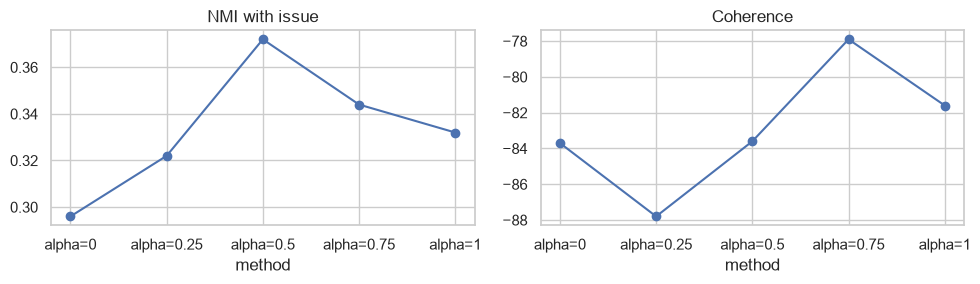

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
alpha_table.plot(x='method', y='NMI_issue', marker='o', ax=ax[0], legend=False, title='NMI with issue')
alpha_table.plot(x='method', y='coherence', marker='o', ax=ax[1], legend=False, title='Coherence')
plt.tight_layout()
plt.show()

I pick `alpha` from this table: I want a mix that is at least as good as both extremes.
If the rows are close, I use 0.5 and let the reading of the clusters decide.

In [ ]:
ALPHA = 0.5
Z_hybrid = combine(ALPHA)
Z_hybrid.shape

(20551, 584)

## 7. Reduce the dimensions (UMAP)

Clustering in 484 dimensions is hard because all distances look similar.
UMAP squeezes the data into 10 dimensions while keeping neighbours together, and I cluster in that space.
I also make a 2D version, only for plotting.

In [ ]:
import umap

reducer = umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, metric='cosine', random_state=SEED)
Z_low = reducer.fit_transform(Z_hybrid)
Z_low.shape

(20551, 10)

In [ ]:
Z_2d = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, metric='cosine', random_state=SEED).fit_transform(Z_hybrid)
Z_2d.shape

(20551, 2)

## 8. Clustering approaches

I try five methods and keep all the labels in one dictionary, so I can compare them at the end.

In [ ]:
results = {}
scores = []

### 8.1 K-Means

K-Means needs the number of clusters. I try several values and look at the inertia (how tight the clusters are) and the silhouette.

In [ ]:
ks = list(range(8, 33, 4))
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=3, random_state=SEED).fit(Z_low)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z_low, km.labels_, sample_size=5000, random_state=SEED))

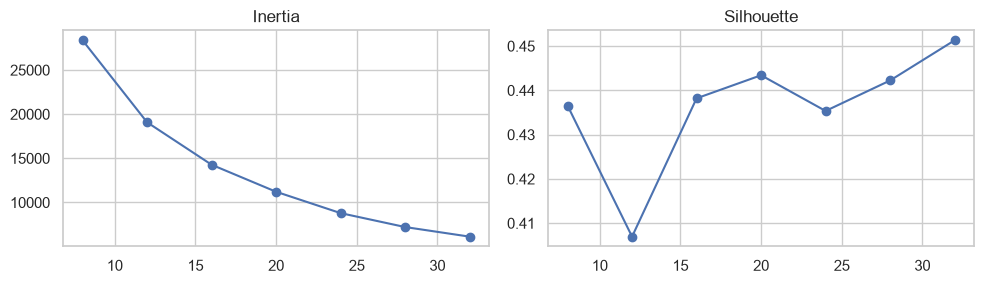

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ks, inertia, marker='o'); ax[0].set_title('Inertia')
ax[1].plot(ks, sil, marker='o'); ax[1].set_title('Silhouette')
plt.tight_layout()
plt.show()

There is no clear elbow, which is common with text. I use 16 clusters. That is a bit more than I expect to need in the end, and I can merge similar clusters later.

In [ ]:
K = 20
results['kmeans'] = KMeans(K, n_init=5, random_state=SEED).fit_predict(Z_low)
scores.append(evaluate(results['kmeans'], 'kmeans', Z_hybrid))

In [ ]:
results['kmeans']

array([15,  3, 13, ..., 10,  2, 10], shape=(20551,), dtype=int32)

<Axes: >

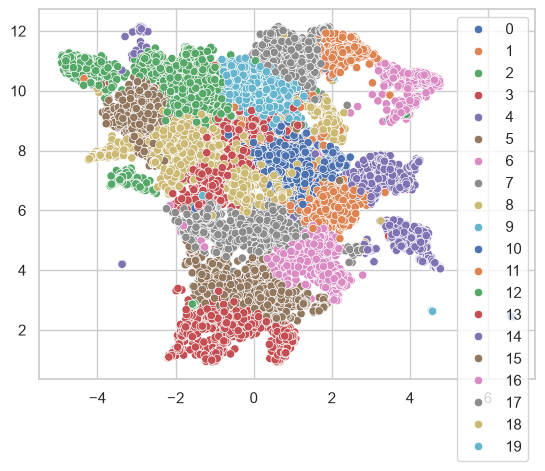

In [ ]:
sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=results['kmeans'], palette=sns.color_palette())

### 8.2 Agglomerative (Ward)

It starts with every complaint alone and merges the closest groups step by step.
I give it a neighbour graph so it merges only nearby points, which also keeps memory low.

In [ ]:
graph = kneighbors_graph(Z_low, n_neighbors=15, include_self=False)
ward = AgglomerativeClustering(n_clusters=K, linkage='ward', connectivity=graph)
results['ward'] = ward.fit_predict(Z_low)
scores.append(evaluate(results['ward'], 'ward', Z_hybrid))

<Axes: >

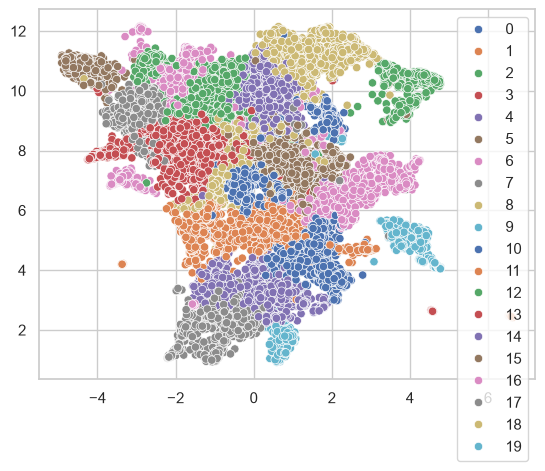

In [ ]:
sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=results['ward'], palette=sns.color_palette())

### 8.3 HDBSCAN

It finds dense areas by itself, so I do not set the number of clusters.
Complaints that are not in a dense area get label -1 (unassigned). This is useful: those are the "unclear" complaints.
The main setting is the minimum cluster size, so I try a few.
If too many complaints end up unassigned, a smaller `min_samples` or `cluster_selection_method='leaf'` usually helps.

In [ ]:
hdb_runs = {}
for mcs in [100, 150, 200, 250]:
    hdb_runs[mcs] = HDBSCAN(min_cluster_size=mcs, min_samples=10).fit_predict(Z_low)
    lab = hdb_runs[mcs]
    print(mcs, '-> clusters:', lab.max() + 1, '| unassigned %:', round((lab == -1).mean() * 100, 1))

100 -> clusters: 38 | unassigned %: 36.2
150 -> clusters: 31 | unassigned %: 38.8
200 -> clusters: 23 | unassigned %: 34.0
250 -> clusters: 18 | unassigned %: 36.1


In [ ]:
MCS = 200
results['hdbscan'] = hdb_runs[MCS]
scores.append(evaluate(results['hdbscan'], 'hdbscan', Z_hybrid))

### 8.5 NMF on TF-IDF (baseline)

The classical topic model, using only the words. It is my reference to see if the embeddings really help.

In [ ]:
nmf = NMF(K, init='nndsvd', random_state=SEED, max_iter=400)
W = nmf.fit_transform(X)
results['nmf'] = W.argmax(axis=1)
scores.append(evaluate(results['nmf'], 'nmf', Z_hybrid))

## 9. Comparing the methods

In [ ]:
pd.DataFrame(scores).set_index('method')

,clusters,unassigned_%,largest_%,NMI_issue,coherence,silhouette
method,,,,,,
kmeans,20,0.0,9.9,0.375,-72.500000,0.041
ward,20,0.0,9.5,0.380,-76.800003,0.043
hdbscan,23,34.0,23.1,0.435,-84.400002,0.069
nmf,20,0.0,11.1,0.276,-85.300003,0.051


Do the methods find the same groups? ARI is 1 when two labelings are identical and about 0 when they are unrelated.

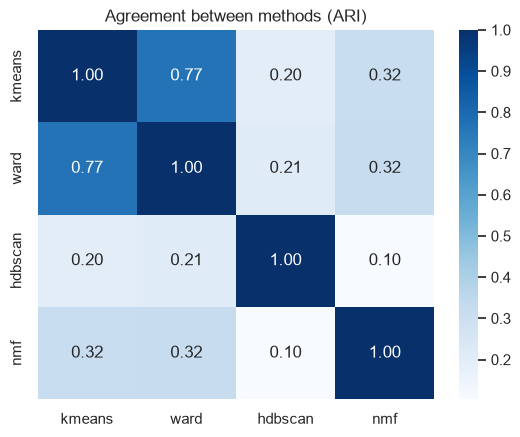

In [ ]:
names = list(results)
ari = pd.DataFrame([[adjusted_rand_score(results[a], results[b]) for b in names] for a in names],
                   index=names, columns=names)
sns.heatmap(ari, annot=True, fmt='.2f', cmap='Blues')
plt.title('Agreement between methods (ARI)')
plt.show()

Is K-Means stable? If I change the random seed, do I get the same clusters?

In [ ]:
a = KMeans(K, n_init=3, random_state=1).fit_predict(Z_low)
b = KMeans(K, n_init=3, random_state=2).fit_predict(Z_low)
round(adjusted_rand_score(a, b), 3)

0.753

## 10. Reading the clusters

The scores only help so much. The real test is whether the complaints in a cluster talk about the same thing.
I choose one method to inspect (I can change `CHOSEN` and run the cells again).

In [ ]:
CHOSEN = 'kmeans'
labels = results[CHOSEN]

In [ ]:
def summarize(labels, topn=8):
    rows = []
    for c, idx in cluster_top_terms(labels, topn).items():
        members = df[labels == c]
        rows.append({'cluster': c, 'size': len(members), 'top_terms': ', '.join(terms[idx]),
                     'top_issue': members['issue'].mode()[0], 'top_product': members['product_group'].mode()[0]})
    return pd.DataFrame(rows).sort_values('size', ascending=False)

In [ ]:
summary = summarize(labels)
summary

,cluster,size,top_terms,top_issue,top_product
3,3,2040,"loan, mortgage, modification, home, property, sale, escrow, foreclosure","Loan modification,collection,foreclosure",Mortgage
2,2,1919,"money, atm, claim, wire, transfer, transaction, debit, debit card",Managing an account,Checking/savings
8,8,1716,"checking, closed, branch, open, checking account, deposit, savings, close",Closing an account,Checking/savings
17,17,1525,"dispute, merchant, charge, disputed, refund, company, services, charged",Problem with a purchase shown on your statement,Credit/prepaid card
15,15,1372,"mortgage, loan, bankruptcy, payments, home, foreclosure, morgan, jp","Loan servicing, payments, escrow account",Mortgage
7,7,1352,"debt, reporting, report, credit report, collection, bureaus, credit reporting, credit bureaus",Incorrect information on your report,Debt collection
5,5,1285,"check, deposited, funds, checks, deposit, cashed, hold, money",Managing an account,Checking/savings
9,9,1279,"charges, fraud, fraudulent, transactions, charge, unauthorized, debit, fraudulent charges",Problem with a purchase shown on your statement,Credit/prepaid card
10,10,1185,"cards, limit, credit cards, score, closed, credit card, credit limit, accounts",Closing your account,Credit/prepaid card
16,16,1156,"late, payment, auto, car, payments, late payment, vehicle, loan",Incorrect information on your report,Credit reporting


In [ ]:
def show_examples(labels, c, n=3):
    for t in df.loc[labels == c, 'text'].sample(n, random_state=SEED):
        print('-', t[:300], '\n')

In [ ]:
show_examples(labels, summary['cluster'].iloc[0])

- My mortgage loan has an escrow account. Chase Bank charges 17 % cushion amount on the escrow account. My yearly overage on taxes and insurance run about 3 %. In effect I am loaning the bank approx 14 % free gratis.If all banks do this, it amounts to billions a year loaned to banks for free. Today lo 

- It sure would be nice if someone would finally help m for a change. It is obvious that JP Morgan Chase does not give a XXXX about their customers and leaving people homeless. I have written previously and WILL CONTINUE TO REPORT JP Morgan Chase until we receive a satisfactory resolution. JP Morgan C 

- I have a problem with Chase.I submitted my complaint before that our mortgage monthly payment is about {$2700.00} and changed. Our interest has been 8.25 since with refinance by chase. We were told that after refinance mortgage our interest will be reduce after two years but that never happened. We  



In [ ]:
show_examples(labels, summary['cluster'].iloc[1])

- XX/XX/6000 dollars They said that they were going to let me know of a second review on releasing my funds but never called me back and I have done everything they have asked my they still havent sent the money in the mail. 

- on XX/XX/19 at XXXX my wallet was stolen from my purse at an after hour spot by who me and friends had to share a section with. According to witnesses XXXX friends ) a week later due to me being in intoxicated he followed me to the ATM ( i did not know he was behind me whole time ) he watched me put 

- I had 2 deposits made in my behalf through the Chase mobile banking app. The first deposit was made on XX/XX/XXXX in the amount of {$1400.00}. The second deposit was made on XX/XX/XXXX {$1600.00}. Both checks that were deposited were copies of a prior deposit and modified to attempt to be passed thr 



I also check how pure each cluster is compared with the issue chosen by the customer.
A cluster where one issue is 90% of the complaints is very clear. A cluster with many issues is either mixed or a theme that the drop-down does not capture.

In [ ]:
purity = (df.assign(c=labels)[labels >= 0].groupby('c')['issue']
          .agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(2))
purity.sort_values()

c
13    0.12
1     0.16
18    0.16
15    0.18
16    0.19
7     0.20
3     0.22
8     0.29
10    0.29
14    0.30
12    0.30
6     0.30
2     0.35
9     0.37
5     0.38
4     0.42
11    0.45
19    0.46
0     0.51
17    0.55
Name: issue, dtype: float64

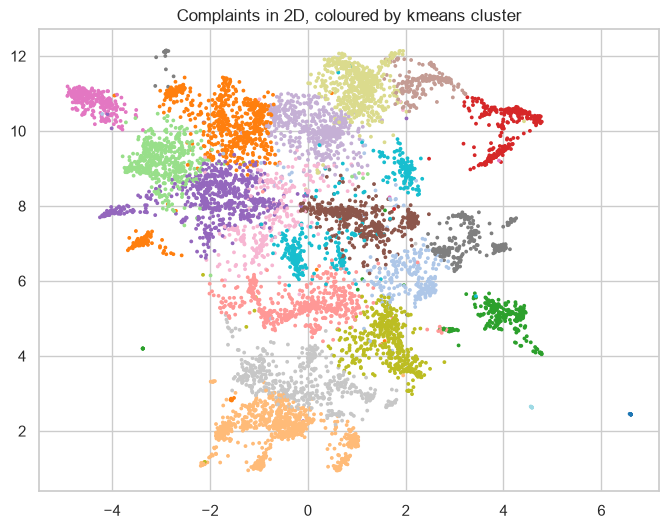

In [ ]:
rng = np.random.RandomState(SEED)
sample = rng.choice(len(df), 8000, replace=False)
plt.figure(figsize=(8, 6))
plt.scatter(Z_2d[sample, 0], Z_2d[sample, 1], c=labels[sample], cmap='tab20', s=3)
plt.title(f'Complaints in 2D, coloured by {CHOSEN} cluster')
plt.show()

## 11. Name the clusters with an LLM

Reading 20 clusters by hand is slow, so I ask an LLM for a first draft name.
For each cluster it gets that cluster's own top words and 5 example complaints, and returns a short name, a one-sentence description and whether the examples look mixed.
These names are only a starting point: the final taxonomy in section 12 is my decision, based on the top words, the examples and these names.

In [ ]:
import json
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv('../.env')
client = OpenAI()
CHAT_MODEL = 'gpt-4o-mini'

def name_cluster(top_terms, examples):
    prompt = (f"Top words: {top_terms}\n\nExample complaints:\n" + "\n---\n".join(examples) +
              '\n\nReply as JSON: {"name": short topic name, "description": one sentence, "mixed": true if the examples are about different problems}')
    resp = client.chat.completions.create(model=CHAT_MODEL, messages=[{'role': 'user', 'content': prompt}],
                                          response_format={'type': 'json_object'})
    return json.loads(resp.choices[0].message.content)

In [ ]:
# name every cluster, using its own top words and a fixed sample of its complaints
cluster_names = {}
for _, row in summary.iterrows():
    c = int(row['cluster'])
    examples = df.loc[labels == c, 'text'].sample(5, random_state=SEED).str[:1000].tolist()
    cluster_names[c] = name_cluster(row['top_terms'], examples)

cluster_names

In [ ]:
Path('../data/interim').mkdir(parents=True, exist_ok=True)
with open('../data/interim/cluster_names.json', 'w', encoding='utf-8') as f:
    json.dump(cluster_names, f, indent=4)

In [ ]:
summary['llm_name'] = summary['cluster'].map(lambda c: cluster_names[c]['name'])
summary['mixed'] = summary['cluster'].map(lambda c: cluster_names[c]['mixed'])

In [ ]:
summary[['cluster', 'size', 'top_terms', 'llm_name', 'mixed']]

## 12. From clusters to the final taxonomy

The topics come from the cluster names saved in section 11 (`cluster_names.json`): each cluster's name becomes its topic and its description becomes the topic definition.
Clusters that share the same name become one topic, so to merge two clusters I give them the same name in that file (and edit the description if needed).
That keeps the taxonomy decision in one reviewable file instead of hard-coded in the notebook.

In [ ]:
# cluster_names.json: {cluster id: {"name": ..., "description": ..., "mixed": ...}}
import json
cluster_names = {int(c): v for c, v in json.load(open('../data/interim/cluster_names.json', encoding='utf-8')).items()}
merge_map = {c: v['name'] for c, v in cluster_names.items()}          # K-Means cluster id -> topic
pd.Series(merge_map).sort_index()

NameError: name 'json' is not defined

Every topic gets a one-line definition: the description of its cluster (the first one when several clusters share a name).
The LLM in the next notebook labels complaints with these definitions, so they matter more than the names.

In [ ]:
taxonomy = {}
for c, v in cluster_names.items():
    taxonomy.setdefault(v['name'], v['description'])
pd.Series(taxonomy)

In [ ]:
df['kmeans_topic'] = pd.Series(labels).map(merge_map).values

clusters_per_topic = pd.Series(merge_map).groupby(lambda c: merge_map[c]).apply(lambda s: sorted(s.index))
topic_table = pd.DataFrame({'clusters': clusters_per_topic, 'complaints': df['kmeans_topic'].value_counts()})
topic_table['share_pct'] = (topic_table['complaints'] / len(df) * 100).round(1)
topic_table.sort_values('complaints', ascending=False)

In [ ]:
pd.crosstab(df['kmeans_topic'], df['product_group'], normalize='index').round(2)

If a topic is dominated by one product, it describes a clear problem; topics that spread over several products are cross-product problems that the product field alone would hide.

**This mapping is a seed, not the final label.** The clusters are mixed, so not every complaint in a cluster is about the cluster's topic.
In the next notebook an LLM labels complaints one by one using these definitions, and `kmeans_topic` is only used as a sanity check.

## 13. Save

- `complaints_clusters.csv`: the cluster of every method, plus the taxonomy topic of the K-Means cluster (`kmeans_topic`)
- `cluster_summary.csv` and `method_comparison.csv`: the tables above
- `taxonomy.json`: the 12 topics and their definitions, used by the labelling notebook and the ops agent
- `cluster_to_topic.json`: the K-Means cluster to topic mapping, used by the ops agent to turn the classifier's cluster into a topic

In [ ]:
out = df[['complaint_id']].copy()
for name, lab in results.items():
    out[name] = lab
out['kmeans_topic'] = df['kmeans_topic'].values
Path('../data/interim').mkdir(parents=True, exist_ok=True)
out.to_csv('../data/interim/complaints_clusters.csv', index=False)
out.shape

In [ ]:
Path('../data/interim').mkdir(parents=True, exist_ok=True)
summary.to_csv('../data/interim/cluster_summary.csv', index=False)
pd.DataFrame(scores).to_csv('../data/interim/method_comparison.csv', index=False)
with open('../data/interim/taxonomy.json', 'w', encoding='utf-8') as f:
    json.dump(taxonomy, f, indent=2)
with open('../data/interim/cluster_to_topic.json', 'w', encoding='utf-8') as f:
    json.dump(merge_map, f, indent=2)